In [3]:
%pip -q install "fastf1>=3.6,<4" 
%pip install scikit-learn "xgboost>=3.0,<4" matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
    --------------------------------------- 1.0/48.9 MB 5.6 MB/s eta 0:00:09
   - -------------------------------------- 1.8/48.9 MB 4.8 MB/s eta 0:00:10
   -- ------------------------------------- 3.1/48.9 MB 5.2 MB/s eta 0:00:09
   --- ------------------------------------ 4.2/48.9 MB 5.3 MB/s eta 0:00:09
   ---- ----------------------------------- 5.5/48.9 MB 5.4 MB/s eta 0:00:09
   ----- ---------------------------------- 6.6/48.9 MB 5.4 MB/s eta 0:00:08
   ------ --------------------------------- 7.6/48.9 MB 5.3 MB/s eta 0:00:08
   ------- -------------------------------- 8.7/48.9 MB 5.3 MB/s eta 0:00:08
   ------- -------------------------------- 9.2/48.9 MB 5.4 MB/s eta 0:00:08
   -------- ------------------------------- 10.2/48.9 MB 5.0 MB/s eta 0:00:08
   --------- ------------------------------ 11.3/48.9 MB 5.0 MB/s eta 0:00:08
   ---------- ----------------------------- 12.6/48.9 MB 5.1 MB/s eta 0:00:08
   

In [1]:
#target year 2026 and test year being 2025
from pathlib import Path
from collections import defaultdict, deque
from datetime import datetime, timezone
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import fastf1, xgboost
from fastf1.ergast import Ergast
from xgboost import XGBClassifier
from IPython.display import display

In [2]:
TARGET_YEAR = 2026
START_YEAR = 2022
TEST_YEAR = TARGET_YEAR - 1
assert START_YEAR <= TARGET_YEAR - 4, "Start atleast 4 years before the target to leave enough training race"
CACHE = Path('Austin_cache'); CACHE.mkdir(exist_ok=True)
fastf1.Cache.enable_cache(str(CACHE))
api = Ergast(limit=100)
print('FastF1', fastf1.__version__, '| XGBoost', xgboost.__version__)

FastF1 3.8.3 | XGBoost 3.4.1


In [5]:
#load and check the race results
def retry(fn):
    for attempt in range(4):
        try:
            return fn()
        except Exception:
            if attempt ==3:
                raise
            time.sleep(2 ** (attempt + 1))


def season_result(year):
    path = CACHE / f'results_{year}_{datetime.now(timezone.utc):%Y%m%d}.csv'
    if path.exists():
        return pd.read_csv(path, parse_dates=["raceDate"])
    page = retry(lambda: api.get_race_results(season=year))
    chunks = []
    received = 0
    while True:
        for (_, meta), result in zip(page.description.iterrows(), page.content):
            frame = pd.DataFrame(result).copy()
            for name in ['season', 'round', 'raceDate', 'circuitId', 'raceName']:
                frame[name] = meta[name]
            chunks.append(frame)
            received += len(frame)
        if received >= page.total_results:
            break
        try:
            time.sleep(0.4)
            page = retry(page.get_next_result_page)
        except ValueError as exc:
            if 'No more data' in str(exc):
                break
            raise
    if not chunks:
        return pd.DataFrame()
    frame = pd.concat(chunks, ignore_index=True).drop_duplicates(['season', 'round', 'driverId'])
    frame.to_csv(path, index=False)
    return frame
    
schedule = retry(lambda: api.get_race_schedule(season=TARGET_YEAR))
austin = schedule.loc[schedule['circuitId'].eq('americas')]
if len (austin) !=1:
    raise ValueError('No unique Austin race in this season schedule. Check TARGET_YEAR.')
target = austin.iloc[0]
target_date = pd.Timestamp(target['raceDate']).tz_localize(None).normalize()
frames = []
for year in range(START_YEAR, TARGET_YEAR + 1):
    part = season_result(year)
    if not part.empty:
        frames.append(part)
    print(f'{year}: {len(part)} driver results loaded')
raw = pd.concat(frames, ignore_index=True)
raw['raceDate'] = pd.to_datetime(raw['raceDate']).dt.tz_localize(None)
today = pd.Timestamp(datetime.now(timezone.utc).date())
history = raw.loc[(raw['raceDate'] < target_date) & (raw['raceDate'] < today)].copy()
history['position'] = pd.to_numeric(history['position'], errors='raise')
history['points'] = pd.to_numeric(history['points'], errors='raise')
history = history.sort_values(['raceDate','season','round','position'])
assert not history.duplicated(['season','round','driverId']).any()
race_checks = history.groupby(['season','round']).agg(
    entrants=('driverId','size'), winners=('position', lambda s: s.eq(1).sum()))
assert race_checks['entrants'].ge(18).all(), 'Incomplete race data detected.'
assert race_checks['winners'].eq(1).all(), 'Each race must have exactly one winner.'
assert history['season'].max() == TARGET_YEAR, 'No current-season results. Check data availability.'
print(f"\nTarget: {target['raceName']} — {target_date.date()}")
print(f"Latest historical race: {history['raceDate'].max().date()}")
latest_race = history.loc[history.raceDate.eq(history.raceDate.max())]
race_preview = latest_race.assign(Driver=latest_race.givenName + ' ' + latest_race.familyName)
display(race_preview[['Driver','constructorName','position','points']].head(5)
        .rename(columns={'constructorName':'Team','position':'Finish','points':'Points'})
        .reset_index(drop=True))

2022: 440 driver results loaded
2023: 440 driver results loaded
2024: 479 driver results loaded
2025: 479 driver results loaded
2026: 374 driver results loaded

Target: United States Grand Prix — 2026-10-25
Latest historical race: 2026-10-11


,Driver,Team,Finish,Points
0,Max Verstappen,Red Bull,1,25.0
1,Charles Leclerc,Ferrari,2,18.0
2,Andrea Kimi Antonelli,Mercedes,3,15.0
3,Lando Norris,McLaren,4,12.0
4,Oscar Piastri,McLaren,5,10.0


In [6]:
#Model learns from driver form(recent finishes, points, wins, podiums, available start)
#Team form - recent combined points and wins
#Austin history 
#Calculate the nine features display-mode: "form"

FEATURES = ['driver_finish_5','driver_points_5','driver_win_rate_5',
            'driver_podium_rate_5','team_points_5','team_win_rate_5',
            'circuit_finish_3','circuit_win_rate_3','driver_history_count']
drivers = defaultdict(lambda: deque(maxlen=5))
teams = defaultdict(lambda: deque(maxlen=5))
circuits = defaultdict(lambda: deque(maxlen=3))

def avg(records, column):
    return float(np.mean([r[column] for r in records])) if records else np.nan

def features(driver, team, circuit):
    d, t, c = drivers[driver], teams[team], circuits[(driver,circuit)]
    return dict(zip(FEATURES, [avg(d,'finish'), avg(d,'points'), avg(d,'win'),
        avg(d,'podium'), avg(t,'points'), avg(t,'win'), avg(c,'finish'),
        avg(c,'win'), len(d)]))

rows = []
for (season, rnd), race in history.groupby(['season','round'], sort=True):
    for _, r in race.iterrows():
        rows.append({**features(r.driverId, r.constructorId, r.circuitId),
            'season': int(season), 'round': int(rnd),
            'race_id': f'{season}-{rnd}', 'raceName': r.raceName,
            'circuitId': r.circuitId, 'driverId': r.driverId,
            'driver': f'{r.givenName} {r.familyName}', 'won': int(r.position == 1)})
    for _, r in race.iterrows():
        record = dict(finish=float(r.position), points=float(r.points),
                      win=int(r.position == 1), podium=int(r.position <= 3))
        drivers[r.driverId].append(record)
        circuits[(r.driverId,r.circuitId)].append(record)
    for team, team_race in race.groupby('constructorId'):
        teams[team].append(dict(points=float(team_race.points.sum()),
                               win=int(team_race.position.eq(1).any())))
data = pd.DataFrame(rows)
data = data.loc[data.season > START_YEAR].copy()
# Show five drivers from the latest historical Austin race.
austin_examples = data.loc[data.circuitId.eq('americas')]
preview = austin_examples.loc[austin_examples.season.eq(austin_examples.season.max())].head(5)
print('Example: inputs available BEFORE the', int(preview.season.iloc[0]), 'Austin race')
display(preview[['driver','driver_finish_5','team_points_5','circuit_finish_3','won']]
        .rename(columns={'driver':'Driver','driver_finish_5':'Recent avg finish',
                         'team_points_5':'Team avg points','circuit_finish_3':'Austin avg finish',
                         'won':'Won the race?'})
        .replace({'Won the race?':{0:'No',1:'Yes'}}).round(1).reset_index(drop=True))
print('This preview shows 3 of the 9 inputs. Lower average finish is better; NaN means no history.')


Example: inputs available BEFORE the 2025 Austin race


,Driver,Recent avg finish,Team avg points,Austin avg finish,Won the race?
0,Max Verstappen,3.0,19.6,1.7,Yes
1,Lando Norris,6.2,26.8,4.0,No
2,Charles Leclerc,8.4,10.0,8.0,No
3,Lewis Hamilton,10.8,10.0,13.7,No
4,Oscar Piastri,6.0,26.8,11.0,No


This preview shows 3 of the 9 inputs. Lower average finish is better; NaN means no history.


In [7]:
def new_model():
    return XGBClassifier(n_estimators=120, max_depth=3,
        learning_rate=0.06, reg_lambda=5.0, min_child_weight=5,
        objective='binary:logistic', eval_metric='logloss',
        tree_method='hist', n_jobs=2, random_state=42)

train = data.loc[data.season < TEST_YEAR]
test = data.loc[data.season == TEST_YEAR].copy()
assert train.race_id.nunique() >= 30 and test.race_id.nunique() >= 10
assert set(train.race_id).isdisjoint(test.race_id)
evaluation_model = new_model().fit(train[FEATURES], train.won)
test['raw_score'] = evaluation_model.predict_proba(test[FEATURES])[:,1]
test['win_score'] = test.raw_score / test.groupby('race_id').raw_score.transform('sum')
picks = test.loc[test.groupby('race_id').win_score.idxmax()]
baseline_rows = test.assign(baseline=test.driver_finish_5.fillna(99))
baseline = baseline_rows.loc[baseline_rows.groupby('race_id').baseline.idxmin()]
print(f'Holdout season: {TEST_YEAR} | {len(picks)} races')
print(f'Model picked winner: {picks.won.sum()}/{len(picks)} ({picks.won.mean():.1%})')
print(f'Recent-form baseline: {baseline.won.sum()}/{len(baseline)} ({baseline.won.mean():.1%})')
metrics = {'test_year': TEST_YEAR, 'test_races': len(picks),
           'winner_accuracy': float(picks.won.mean()),
           'recent_form_baseline_accuracy': float(baseline.won.mean())}

Holdout season: 2025 | 24 races
Model picked winner: 6/24 (25.0%)
Recent-form baseline: 7/24 (29.2%)


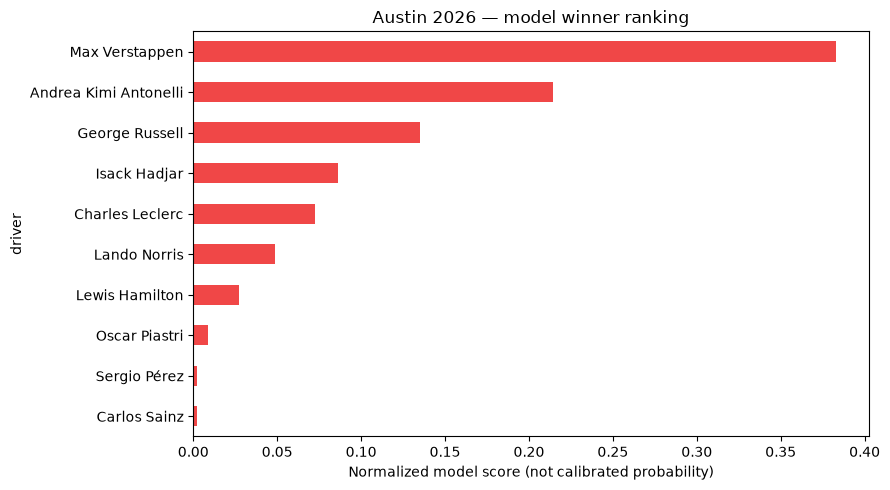


United States Grand Prix 2026: top three model picks
Race date: 2026-10-25 | Results through: 2026-10-11
Entry list: Most recent completed race; confirm substitutions

1. Max Verstappen (Red Bull)
2. Andrea Kimi Antonelli (Mercedes)
3. George Russell (Mercedes)

Ranks reflect winner-model scores, not predicted podium positions.


In [8]:
#title Run the Austin prediction { display-mode: "form" }
model = new_model().fit(data[FEATURES], data.won)
latest = history.loc[history.raceDate.eq(history.raceDate.max())].copy()
entries = latest[['driverId','constructorId','constructorName','givenName','familyName']].copy()
entries['driver'] = entries.givenName + ' ' + entries.familyName
entries = entries.rename(columns={'constructorName':'team'})[['driverId','constructorId','driver','team']]
entry_source = 'Most recent completed race; confirm substitutions'
if Path('austin_entries.csv').exists():
    entries = pd.read_csv('austin_entries.csv')
    assert {'driverId','constructorId','driver','team'} <= set(entries.columns)
    entry_source = 'User-supplied entry list'
assert entries.driverId.is_unique and len(entries) >= 18
assert entries[['driverId','constructorId','driver','team']].notna().all().all()
inputs = pd.DataFrame([features(r.driverId,r.constructorId,'americas') for r in entries.itertuples()])
inputs = pd.concat([entries.reset_index(drop=True), inputs], axis=1)

def predict_field(field, fitted_model=model):
    result = field[['driverId','driver','team']].copy()
    scores = fitted_model.predict_proba(field[FEATURES])[:,1]
    result['win_score'] = scores / scores.sum()
    return result.sort_values('win_score', ascending=False).reset_index(drop=True)

predictions = predict_field(inputs)
assert np.isclose(predictions.win_score.sum(), 1)
ax = predictions.iloc[:10].sort_values('win_score').plot.barh(
    x='driver', y='win_score', legend=False, color='#F04747', figsize=(9,5))
ax.set_title(f'Austin {TARGET_YEAR} — model winner ranking')
ax.set_xlabel('Normalized model score (not calibrated probability)')
plt.tight_layout(); plt.show()
# The classifier estimates relative winner strength, not finishing positions.
final_results = predictions.sort_values("win_score", ascending=False).reset_index(drop=True)
top_three = final_results.head(3)

print(f"\nUnited States Grand Prix {TARGET_YEAR}: top three model picks")
print(f"Race date: {target_date.date()} | Results through: {history.raceDate.max().date()}")
print(f"Entry list: {entry_source}\n")
for rank, row in enumerate(top_three.itertuples(), start=1):
    print(f"{rank}. {row.driver} ({row.team})")
print("\nRanks reflect winner-model scores, not predicted podium positions.")
